<a href="https://colab.research.google.com/github/dhuonggiang209/KHDL-NHOM-8-KTDTCLC-66B/blob/main/%5BKHDL%5D_Nh%C3%B3m_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

# Kết nối Google Drive với Colab
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Khai báo đường dẫn file dữ liệu
file_path = '/content/drive/MyDrive/insurance.csv'

# Đọc dữ liệu
df = pd.read_csv(file_path)

# Hiển thị 5 dòng đầu tiên
display(df.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# Kiểm tra số dòng, số cột và tên các biến
print("Số hàng dữ liệu:", df.shape[0])
print("Số  của dữ liệu:", df.shape[1])
print("Tên các cột:", df.columns.tolist())


Số hàng dữ liệu: 1338
Số  của dữ liệu: 7
Tên các cột: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [ ]:
# Kiểm tra kiểu dữ liệu mỗi biến thuộc kiểu dữ liệu gì
df.info()
print("\nSố giá trị thiếu từng cột:")
print(df.isnull().sum())
print("Tổng số giá trị thiếu là:", df.isnull().sum().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Số giá trị thiếu từng cột:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Tổng số giá trị thiếu là: 0


In [ ]:
# Kiểm tra các dòng trùng lặp
print("Số dòng trùng:", df.duplicated().sum())
# Hiển thị dòng bị trùng:
df[df.duplicated(keep=False)]

Số dòng trùng: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [ ]:
# Thống kê mô tả các biến số
display(df.describe())

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
# Tính tỷ lệ phần trăm dữ liệu thiếu
missing_count = df.isnull().sum()
missing_percent = df.isnull().mean() * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percent
})

display(missing_summary)

,Missing Count,Missing Percentage (%)
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


In [ ]:
# Kiểm tra tính nhất quán của dữ liệu
for col in ['sex', 'smoker', 'region']:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [ ]:
# GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU
# Tạo bản sao để làm sạch, giữ nguyên dữ liệu gốc df của Giai đoạn 1
df_clean = df.copy()
print("Kích thước dữ liệu trước khi làm sạch:", df_clean.shape)

Kích thước dữ liệu trước khi làm sạch: (1338, 7)


In [ ]:
# KIỂM TRA SAI ĐỊNH DẠNG
# Xem kiểu dữ liệu của từng cột
print(df_clean.dtypes)

# Liệt kê các giá trị của 3 biến phân loại để tìm lỗi chính tả, viết hoa, khoảng trắng thừa
for cot in ['sex', 'smoker', 'region']:
    print(cot, ":", df_clean[cot].unique())

# Kiểm tra giá trị vô lý của các biến số
print("Số dòng có tuổi < 18 hoặc > 100:", ((df_clean['age'] < 18) | (df_clean['age'] > 100)).sum())
print("Số dòng có BMI <= 0:", (df_clean['bmi'] <= 0).sum())
print("Số dòng có số con < 0:", (df_clean['children'] < 0).sum())
print("Số dòng có chi phí <= 0:", (df_clean['charges'] <= 0).sum())

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object
sex : ['female' 'male']
smoker : ['yes' 'no']
region : ['southwest' 'southeast' 'northwest' 'northeast']
Số dòng có tuổi < 18 hoặc > 100: 0
Số dòng có BMI <= 0: 0
Số dòng có số con < 0: 0
Số dòng có chi phí <= 0: 0


In [ ]:
# KIỂM TRA GIÁ TRỊ THIẾU
print("Tổng số giá trị thiếu:", df_clean.isnull().sum().sum())
# Không có giá trị thiếu -> không điền. Nếu có, charges sẽ điền bằng Median thay vì Mean
# vì charges lệch phải mạnh (Mean bị kéo lên bởi một số ít chi phí rất cao)
print("Mean charges  :", round(df_clean['charges'].mean(), 2))
print("Median charges:", round(df_clean['charges'].median(), 2))
print("Hệ số lệch (skew) của charges:", round(df_clean['charges'].skew(), 2))

Tổng số giá trị thiếu: 0
Mean charges  : 13270.42
Median charges: 9382.03
Hệ số lệch (skew) của charges: 1.52


In [ ]:
# XỬ LÝ DỮ LIỆU TRÙNG LẶP
# Dòng 195 và 581 trùng cả 7 cột (kể cả chi phí đến 4 chữ số thập phân) -> nhiều khả năng là lỗi nhập liệu
# Xóa bản lặp, giữ lại 1 bản
df_clean = df_clean.drop_duplicates(keep='first').reset_index(drop=True)

# Kiểm tra lại sau khi xóa
print("Số dòng trùng còn lại:", df_clean.duplicated().sum())
print("Kích thước sau khi xóa trùng:", df_clean.shape)

Số dòng trùng còn lại: 0
Kích thước sau khi xóa trùng: (1337, 7)


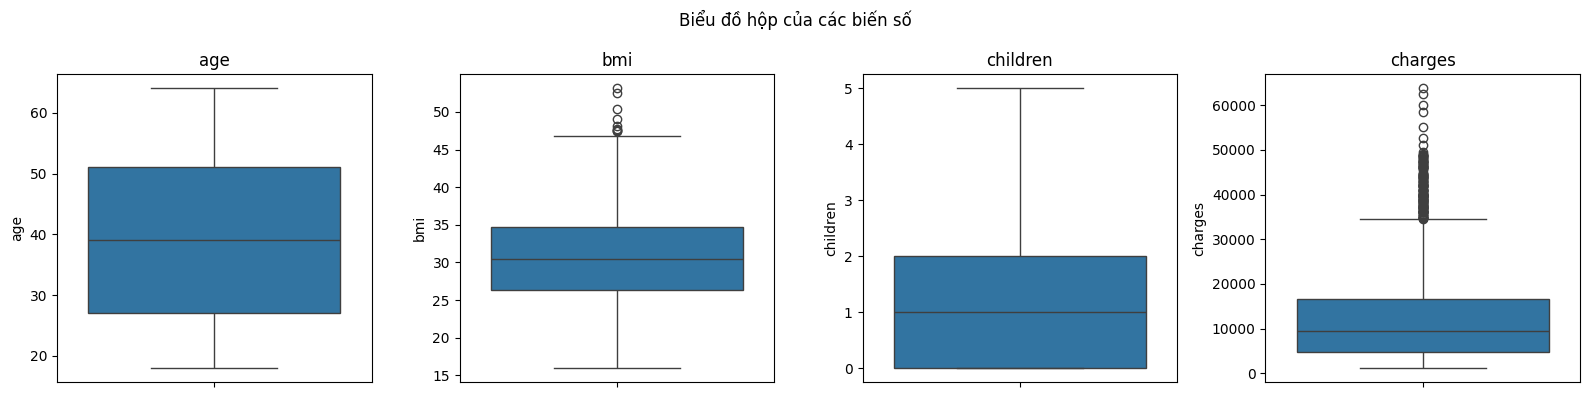

In [ ]:
# PHÁT HIỆN NGOẠI LỆ (OUTLIERS)
# Vẽ biểu đồ hộp cho 4 biến số; các chấm nằm ngoài "râu" của hộp là ngoại lệ
cot_so = ['age', 'bmi', 'children', 'charges']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, cot in zip(axes, cot_so):
    sns.boxplot(y=df_clean[cot], ax=ax)
    ax.set_title(cot)
plt.suptitle('Biểu đồ hộp của các biến số')
plt.tight_layout()
plt.show()

In [ ]:
# Đếm số ngoại lệ bằng quy tắc IQR (Tukey, 1977):
# ngoại lệ là giá trị < Q1 - 1.5*IQR hoặc > Q3 + 1.5*IQR, với IQR = Q3 - Q1
for cot in cot_so:
    Q1 = df_clean[cot].quantile(0.25)
    Q3 = df_clean[cot].quantile(0.75)
    IQR = Q3 - Q1
    can_duoi = Q1 - 1.5 * IQR
    can_tren = Q3 + 1.5 * IQR
    so_ngoai_le = ((df_clean[cot] < can_duoi) | (df_clean[cot] > can_tren)).sum()
    print(f"{cot}: cận dưới = {can_duoi:.2f}, cận trên = {can_tren:.2f}, số ngoại lệ = {so_ngoai_le}")

age: cận dưới = -9.00, cận trên = 87.00, số ngoại lệ = 0
bmi: cận dưới = 13.67, cận trên = 47.32, số ngoại lệ = 9
children: cận dưới = -3.00, cận trên = 5.00, số ngoại lệ = 0
charges: cận dưới = -13120.72, cận trên = 34524.78, số ngoại lệ = 139


In [ ]:
# Xem chi tiết các ngoại lệ của BMI
Q1 = df_clean['bmi'].quantile(0.25)
Q3 = df_clean['bmi'].quantile(0.75)
can_tren_bmi = Q3 + 1.5 * (Q3 - Q1)
display(df_clean[df_clean['bmi'] > can_tren_bmi].sort_values('bmi'))
# BMI 47-53 là béo phì độ III theo WHO (BMI >= 40), giá trị có thật, không phải lỗi -> GIỮ LẠI

,age,sex,bmi,children,smoker,region,charges
543,54,female,47.41,0,yes,southeast,63770.42801
401,47,male,47.52,1,no,southeast,8083.91980
859,37,female,47.60,2,yes,southwest,46113.51100
1087,52,male,47.74,1,no,southeast,9748.91060
286,46,female,48.07,2,no,northeast,9432.92530
116,58,male,49.06,0,no,southeast,11381.32540
846,23,male,50.38,1,no,southeast,2438.05520
1046,22,male,52.58,1,yes,southeast,44501.39820
1316,18,male,53.13,0,no,southeast,1163.46270


Số ngoại lệ charges theo tình trạng hút thuốc:
smoker
yes    136
no       3
Name: count, dtype: int64


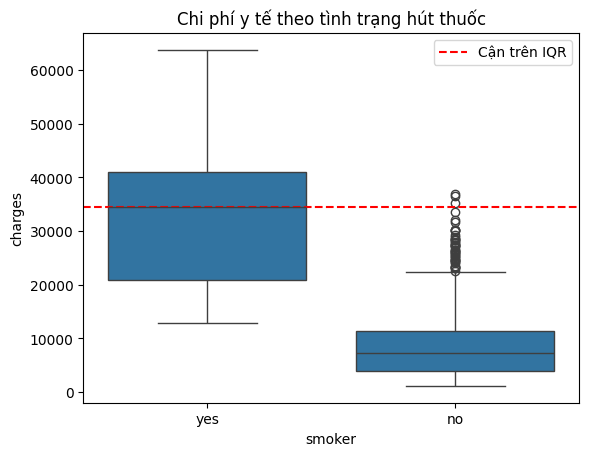

In [ ]:
# Tìm hiểu các ngoại lệ của charges thuộc nhóm khách hàng nào
Q1 = df_clean['charges'].quantile(0.25)
Q3 = df_clean['charges'].quantile(0.75)
can_tren_charges = Q3 + 1.5 * (Q3 - Q1)
ngoai_le_charges = df_clean[df_clean['charges'] > can_tren_charges]

# Đếm số ngoại lệ theo tình trạng hút thuốc
print("Số ngoại lệ charges theo tình trạng hút thuốc:")
print(ngoai_le_charges['smoker'].value_counts())

# Biểu đồ hộp chi phí theo tình trạng hút thuốc, đường đỏ là cận trên IQR
sns.boxplot(data=df_clean, x='smoker', y='charges')
plt.axhline(can_tren_charges, color='red', linestyle='--', label='Cận trên IQR')
plt.title('Chi phí y tế theo tình trạng hút thuốc')
plt.legend()
plt.show()
# Hầu hết ngoại lệ là người hút thuốc -> đây là nhóm khách hàng có thật với chi phí cao,
# không phải lỗi -> GIỮ LẠI (xóa sẽ mất gần một nửa số người hút thuốc)

In [ ]:
# MÃ HÓA BIẾN PHÂN LOẠI (ENCODING)
# Tạo bản riêng df_model để mã hóa; df_clean giữ nguyên chữ để vẽ biểu đồ ở Giai đoạn 3
df_model = df_clean.copy()

# sex và smoker chỉ có 2 giá trị -> mã hóa 0/1
df_model['sex'] = df_model['sex'].map({'female': 0, 'male': 1})
df_model['smoker'] = df_model['smoker'].map({'no': 0, 'yes': 1})

# region có 4 vùng KHÔNG có thứ tự -> dùng One-hot thay vì đánh số 0,1,2,3
# (đánh số sẽ khiến máy hiểu sai là các vùng có thứ tự hơn kém)
# drop_first=True: bỏ cột northeast làm nhóm gốc, tránh lỗi đa cộng tuyến (bẫy biến giả)
df_model = pd.get_dummies(df_model, columns=['region'], drop_first=True, dtype=int)

display(df_model.head())

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


In [ ]:
# CHUẨN HÓA DỮ LIỆU (SCALING)
from sklearn.preprocessing import StandardScaler

# Dùng StandardScaler: (giá trị - trung bình) / độ lệch chuẩn
# Không dùng MinMaxScaler vì nhạy với giá trị cực trị (như BMI 53.13)
# Chỉ chuẩn hóa 3 biến số đầu vào; không chuẩn hóa biến 0/1 và biến mục tiêu charges
cot_chuan_hoa = ['age', 'bmi', 'children']
scaler = StandardScaler()
df_model[cot_chuan_hoa] = scaler.fit_transform(df_model[cot_chuan_hoa])

# Kiểm tra: sau chuẩn hóa, trung bình ≈ 0 và độ lệch chuẩn ≈ 1
display(df_model[cot_chuan_hoa].describe().round(2))

,age,bmi,children
count,1337.00,1337.00,1337.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.51,-2.41,-0.91
25%,-0.87,-0.72,-0.91
50%,-0.02,-0.04,-0.08
75%,0.84,0.66,0.75
max,1.76,3.68,3.24


In [ ]:
# KIỂM TRA KẾT QUẢ SAU TIỀN XỬ LÝ
print("df_clean (dùng cho Giai đoạn 3):", df_clean.shape)
print("   - Số giá trị thiếu:", df_clean.isnull().sum().sum())
print("   - Số dòng trùng lặp:", df_clean.duplicated().sum())
print("df_model (đã mã hóa và chuẩn hóa):", df_model.shape)
print("   - Các cột:", df_model.columns.tolist())

df_clean (dùng cho Giai đoạn 3): (1337, 7)
   - Số giá trị thiếu: 0
   - Số dòng trùng lặp: 0
df_model (đã mã hóa và chuẩn hóa): (1337, 9)
   - Các cột: ['age', 'sex', 'bmi', 'children', 'smoker', 'charges', 'region_northwest', 'region_southeast', 'region_southwest']


In [ ]:
# GIAI ĐOẠN 3 - BẢNG 1: NGƯỜI HÚT THUỐC CÓ CHI PHÍ BẢO HIỂM CAO HƠN KHÔNG?
# Tách hai nhóm
non_smoker = df_clean[df_clean['smoker'] == 'no']['charges']

smoker = df_clean[df_clean['smoker'] == 'yes']['charges']

# Thống kê mô tả
summary_q1 = df_clean.groupby('smoker')['charges'].agg(
    So_quan_sat='count',
    Trung_binh='mean',
    Trung_vi='median',
    Do_lech_chuan='std',
    Nho_nhat='min',
    Lon_nhat='max')

summary_q1['Q1'] = df_clean.groupby('smoker')['charges'].quantile(0.25)
summary_q1['Q3'] = df_clean.groupby('smoker')['charges'].quantile(0.75)

summary_q1.index = summary_q1.index.map({
    'no': 'Không hút thuốc',
    'yes': 'Hút thuốc'})

print("BẢNG 4.1. THỐNG KÊ CHI PHÍ BẢO HIỂM CỦA NGƯỜI HÚT THUỐC VÀ KHÔNG")
display(summary_q1.round(2))

# Tính mức chênh lệch
mean_no = non_smoker.mean()
mean_yes = smoker.mean()

median_no = non_smoker.median()
median_yes = smoker.median()

mean_diff = mean_yes - mean_no
median_diff = median_yes - median_no

mean_ratio = mean_yes / mean_no
median_ratio = median_yes / median_no

mean_increase = mean_diff / mean_no * 100
median_increase = median_diff / median_no * 100

print("\nSO SÁNH HAI NHÓM")
print(f"Chênh lệch trung bình: {mean_diff:,.2f} USD")
print(f"Chi phí trung bình cao gấp: {mean_ratio:.2f} lần")
print(f"Mức tăng trung bình: {mean_increase:.2f}%")

print(f"\nChênh lệch trung vị: {median_diff:,.2f} USD")
print(f"Chi phí trung vị cao gấp: {median_ratio:.2f} lần")
print(f"Mức tăng trung vị: {median_increase:.2f}%")

BẢNG 4.1. THỐNG KÊ CHI PHÍ BẢO HIỂM CỦA NGƯỜI HÚT THUỐC VÀ KHÔNG


,So_quan_sat,Trung_binh,Trung_vi,Do_lech_chuan,Nho_nhat,Lon_nhat,Q1,Q3
smoker,,,,,,,,
Không hút thuốc,1063,8440.66,7345.73,5992.97,1121.87,36910.61,3988.88,11363.02
Hút thuốc,274,32050.23,34456.35,11541.55,12829.46,63770.43,20826.24,41019.21



SO SÁNH HAI NHÓM
Chênh lệch trung bình: 23,609.57 USD
Chi phí trung bình cao gấp: 3.80 lần
Mức tăng trung bình: 279.71%

Chênh lệch trung vị: 27,110.62 USD
Chi phí trung vị cao gấp: 4.69 lần
Mức tăng trung vị: 369.07%


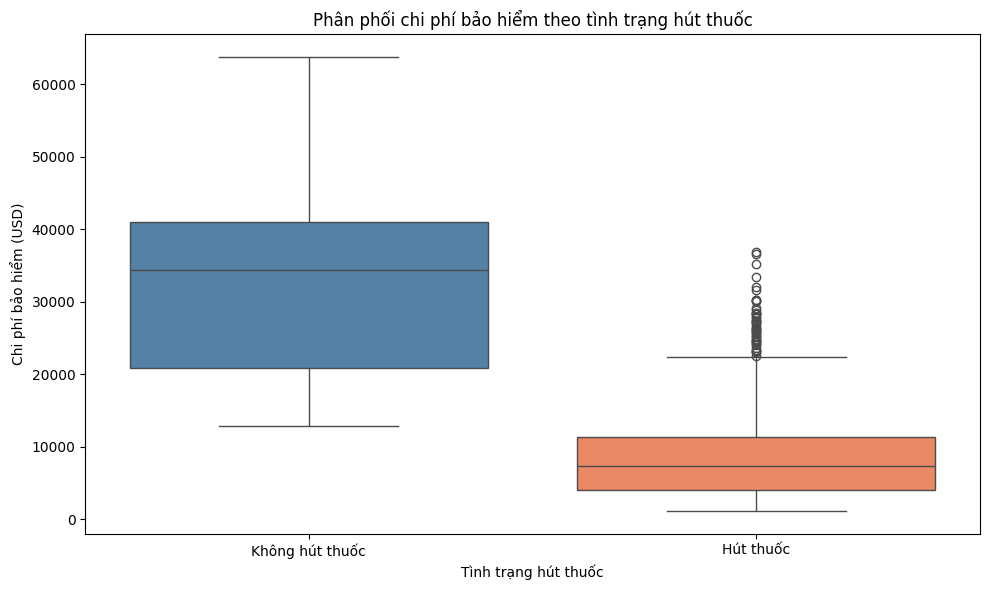

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='smoker',
    y='charges',
    hue='smoker',
    palette=['steelblue', 'coral'],
    legend=False
)

plt.title('Phân phối chi phí bảo hiểm theo tình trạng hút thuốc')
plt.xlabel('Tình trạng hút thuốc')
plt.ylabel('Chi phí bảo hiểm (USD)')
plt.xticks([0, 1], ['Không hút thuốc', 'Hút thuốc'])

plt.tight_layout()
plt.show()

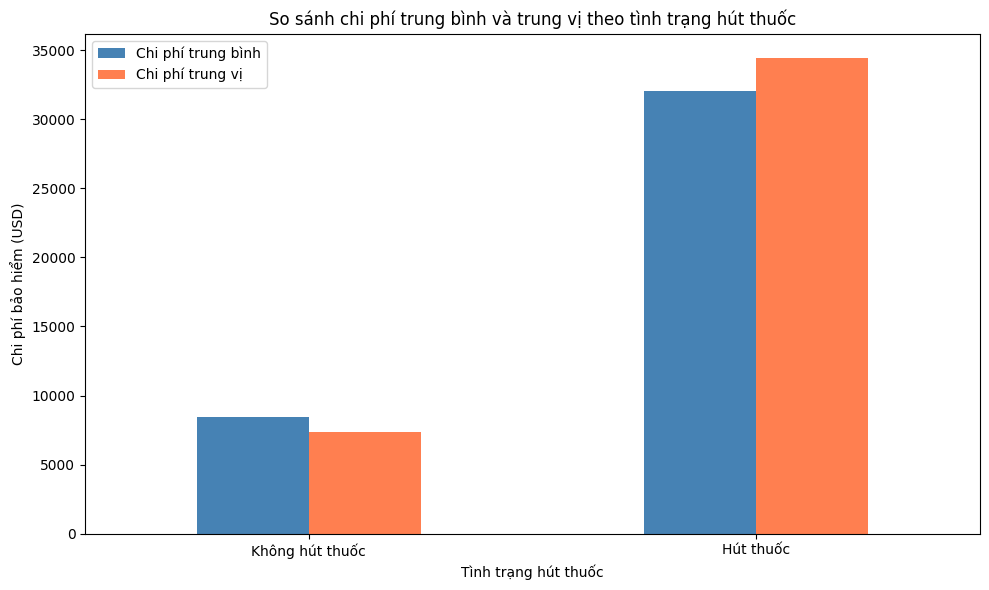

In [ ]:
# Tính trung bình và trung vị theo nhóm
bang_ve = df_clean.groupby('smoker')['charges'].agg(
    Mean='mean',
    Median='median'
)

# Vẽ biểu đồ cột
bang_ve.plot(
    kind='bar',
    figsize=(10, 6),
    color=['steelblue', 'coral']
)

plt.title('So sánh chi phí trung bình và trung vị theo tình trạng hút thuốc')
plt.xlabel('Tình trạng hút thuốc')
plt.ylabel('Chi phí bảo hiểm (USD)')
plt.xticks([0, 1], ['Không hút thuốc', 'Hút thuốc'], rotation=0)
plt.legend(['Chi phí trung bình', 'Chi phí trung vị'])
plt.tight_layout()
plt.show()

In [ ]:

from scipy import stats
import numpy as np

alpha = 0.05

# 1. Kiểm định Mann-Whitney U
u_stat, mw_p = stats.mannwhitneyu(
    smoker, non_smoker, alternative='greater'
)

rank_biserial = 2*u_stat/(len(smoker)*len(non_smoker))-1

# 2. Kiểm định Welch's t-test
t_stat, t_p = stats.ttest_ind(
    smoker, non_smoker,
    equal_var=False, alternative='greater'
)

# Khoảng tin cậy 95%
a = smoker.var(ddof=1)/len(smoker)
b = non_smoker.var(ddof=1)/len(non_smoker)

df_w = (a+b)**2/(a**2/(len(smoker)-1)+b**2/(len(non_smoker)-1))
se = np.sqrt(a+b)
t_crit = stats.t.ppf(0.975, df_w)

diff = smoker.mean()-non_smoker.mean()

# 3. In kết quả kiểm định
print("KẾT QUẢ KIỂM ĐỊNH")
print("-"*50)
print(f"Mann-Whitney U: {u_stat:,.2f}")
print(f"P-value: {mw_p:.6e}")
print(f"Rank-biserial: {rank_biserial:.4f}")
print(f"Welch's t-test: {t_stat:.4f}")
print(f"P-value: {t_p:.6e}")
print(f"Khoảng tin cậy 95%: [{diff-t_crit*se:,.2f}; {diff+t_crit*se:,.2f}] USD")

print("\nKẾT LUẬN:")
print("Bác bỏ H0." if mw_p < alpha else "Chưa đủ cơ sở bác bỏ H0.")


KẾT QUẢ KIỂM ĐỊNH
--------------------------------------------------
Mann-Whitney U: 283,859.00
P-value: 2.873506e-130
Rank-biserial: 0.9492
Welch's t-test: 32.7423
P-value: 3.130860e-103
Khoảng tin cậy 95%: [22,190.79; 25,028.35] USD

KẾT LUẬN:
Bác bỏ H0.


In [ ]:
# 4. PHÂN TÍCH CHI PHÍ CAO THEO IQR

q1 = df_clean['charges'].quantile(0.25)
q3 = df_clean['charges'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

# Xác định các quan sát có chi phí cao theo ngưỡng IQR
chi_phi_cao = df_clean['charges'] > upper_bound

# Thống kê số lượng và tỷ lệ chi phí cao theo tình trạng hút thuốc
outlier_summary = df_clean.groupby('smoker').agg(
    Tong_quan_sat=('charges', 'count'))
outlier_summary['Chi_phi_cao'] = chi_phi_cao.groupby(df_clean['smoker']).sum()
outlier_summary['Ty_le (%)'] = (
    outlier_summary['Chi_phi_cao'] / outlier_summary['Tong_quan_sat'] * 100)

print(f"Q1: {q1:,.2f} USD")
print(f"Q3: {q3:,.2f} USD")
print(f"IQR: {iqr:,.2f} USD")
print(f"Ngưỡng chi phí cao: {upper_bound:,.2f} USD")

print("\nBẢNG PHÂN TÍCH CHI PHÍ CAO")
display(outlier_summary.round(2))

# Tỷ trọng người hút thuốc trong tổng số quan sát có chi phí cao
total_high = int(chi_phi_cao.sum())
high_yes = int(((df_clean['smoker'] == 'yes') & chi_phi_cao).sum())

print(f"\nTổng số quan sát chi phí cao: {total_high}")
if total_high > 0:
    print(f"Số người hút thuốc: {high_yes}")
    print(f"Tỷ lệ người hút thuốc trong nhóm chi phí cao: {high_yes / total_high * 100:.2f}%")

Q1: 4,746.34 USD
Q3: 16,657.72 USD
IQR: 11,911.37 USD
Ngưỡng chi phí cao: 34,524.78 USD

BẢNG PHÂN TÍCH CHI PHÍ CAO


,Tong_quan_sat,Chi_phi_cao,Ty_le (%)
smoker,,,
no,1063,3,0.28
yes,274,136,49.64



Tổng số quan sát chi phí cao: 139
Số người hút thuốc: 136
Tỷ lệ người hút thuốc trong nhóm chi phí cao: 97.84%


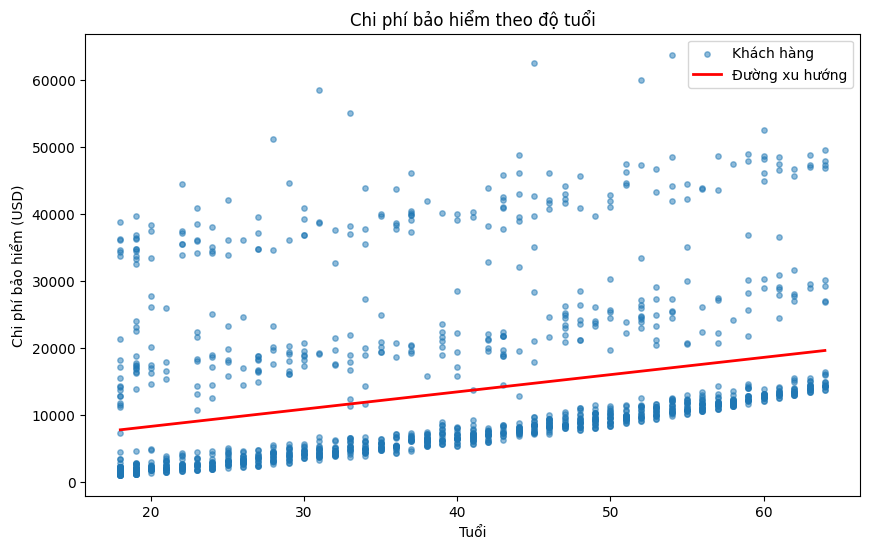

Chi phí = 257.23 × tuổi + 3,190.02


In [ ]:
# GIAI ĐOẠN 3 – BẢNG 2: CHI PHÍ BẢO HIỂM THEO ĐỘ TUỔI
# Scatter plot tuổi – chi phí (dùng df_clean đã làm sạch ở Giai đoạn 2)
plt.figure(figsize=(10, 6))
plt.scatter(df_clean['age'], df_clean['charges'],
            alpha=0.5, s=15, label='Khách hàng')

# Đường xu hướng tuyến tính: chi phí = độ dốc × tuổi + hệ số chặn
do_doc, he_so_chan = np.polyfit(df_clean['age'], df_clean['charges'], 1)
truc_tuoi = np.arange(18, 65)
plt.plot(truc_tuoi, do_doc * truc_tuoi + he_so_chan,
         color='red', linewidth=2, label='Đường xu hướng')

plt.title('Chi phí bảo hiểm theo độ tuổi')
plt.xlabel('Tuổi'); plt.ylabel('Chi phí bảo hiểm (USD)'); plt.legend()
plt.show()
print(f"Chi phí = {do_doc:,.2f} × tuổi + {he_so_chan:,.2f}")

In [ ]:
# Kiểm định giả thuyết, mức ý nghĩa 5%
# H0: tuổi và chi phí không tương quan; H1: có tương quan
from scipy import stats
# Pearson: tương quan tuyến tính; Spearman: tương quan đơn điệu
r_p, p_p = stats.pearsonr(df_clean['age'], df_clean['charges'])
r_s, p_s = stats.spearmanr(df_clean['age'], df_clean['charges'])
print(f"Pearson : r = {r_p:.3f}, p-value = {p_p:.2e}")
print(f"Spearman: rho = {r_s:.3f}, p-value = {p_s:.2e}")
print("=> Bác bỏ H0" if max(p_p, p_s) < 0.05 else "=> Chưa bác bỏ H0")

Pearson : r = 0.298, p-value = 6.98e-29
Spearman: rho = 0.534, p-value = 3.19e-99
=> Bác bỏ H0


In [ ]:
# Thống kê chi phí theo 4 nhóm tuổi (biến riêng, không thêm cột vào df_clean)
nhom_tuoi = pd.cut(df_clean['age'], bins=[17, 29, 39, 49, 64],
                   labels=['18-29', '30-39', '40-49', '50-64'])
tk = df_clean.groupby(nhom_tuoi, observed=True)['charges'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
display(tk)
# So sánh nhóm 50-64 với nhóm 18-29
gap = tk.loc['50-64'] / tk.loc['18-29']
print("Trung vị gấp:", round(gap['median'], 2), "lần")
print("Trung bình gấp:", round(gap['mean'], 2), "lần")

,count,mean,median,std,min,max
age,,,,,,
18-29,416,9200.62,3220.37,11473.33,1121.87,51194.56
30-39,257,11738.78,6082.40,11789.07,3260.20,58571.07
40-49,279,14399.20,8606.22,11639.98,5415.66,62592.87
50-64,385,17902.55,12629.90,11631.77,8442.67,63770.43


Trung vị gấp: 3.92 lần
Trung bình gấp: 1.95 lần


In [ ]:
# Tỷ lệ chi phí cao và tỷ lệ hút thuốc theo nhóm tuổi
# Ngưỡng chi phí cao = cận trên IQR của charges
Q1_cp, Q3_cp = df_clean['charges'].quantile([0.25, 0.75])
nguong = Q3_cp + 1.5 * (Q3_cp - Q1_cp)
print(f"Ngưỡng chi phí cao: {nguong:,.2f} USD")

chi_phi_cao = (df_clean['charges'] > nguong).groupby(nhom_tuoi, observed=True)
hut_thuoc = (df_clean['smoker'] == 'yes').groupby(nhom_tuoi, observed=True)
display(pd.DataFrame({'Số người': chi_phi_cao.size(),
                      'Số chi phí cao': chi_phi_cao.sum(),
                      '% chi phí cao': (chi_phi_cao.mean() * 100).round(1),
                      '% hút thuốc': (hut_thuoc.mean() * 100).round(1)}))

Ngưỡng chi phí cao: 34,524.78 USD


,Số người,Số chi phí cao,% chi phí cao,% hút thuốc
age,,,,
18-29,416,34,8.2,20.7
30-39,257,29,11.3,22.6
40-49,279,32,11.5,22.2
50-64,385,44,11.4,17.7


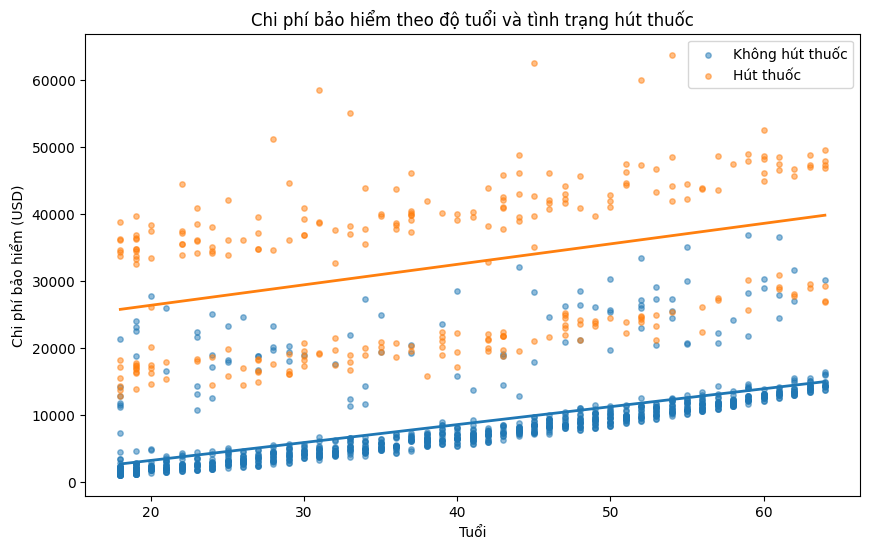

In [ ]:
# Scatter plot tuổi – chi phí, tách theo tình trạng hút thuốc
plt.figure(figsize=(10, 6))
nhan = [('no', 'tab:blue', 'Không hút thuốc'), ('yes', 'tab:orange', 'Hút thuốc')]
for nhom, mau, ten in nhan:
    dl = df_clean[df_clean['smoker'] == nhom]
    plt.scatter(dl['age'], dl['charges'], alpha=0.5, s=15, color=mau, label=ten)
    # Đường xu hướng riêng cho từng nhóm
    doc, chan = np.polyfit(dl['age'], dl['charges'], 1)
    plt.plot(truc_tuoi, doc * truc_tuoi + chan, color=mau, linewidth=2)
plt.title('Chi phí bảo hiểm theo độ tuổi và tình trạng hút thuốc')
plt.xlabel('Tuổi'); plt.ylabel('Chi phí bảo hiểm (USD)'); plt.legend()
plt.show()


In [ ]:
# So sánh xu hướng theo tuổi giữa hai nhóm hút thuốc / không hút thuốc
ket_qua = []
for nhom in ['no', 'yes']:
    dl = df_clean[df_clean['smoker'] == nhom]
    tre = dl.loc[dl['age'] <= 29, 'charges'].median()   # trung vị nhóm 18-29
    gia = dl.loc[dl['age'] >= 50, 'charges'].median()   # trung vị nhóm 50-64
    doc = np.polyfit(dl['age'], dl['charges'], 1)[0]    # tăng thêm mỗi năm tuổi
    rho = stats.spearmanr(dl['age'], dl['charges'])[0]
    ket_qua.append([nhom, len(dl), round(doc, 2), round(rho, 3),
                    round(tre, 2), round(gia, 2), round(gia / tre, 2)])
cot = ['smoker', 'Số người', 'USD/năm tuổi', 'Spearman',
       'Trung vị 18-29', 'Trung vị 50-64', 'Gấp (lần)']
display(pd.DataFrame(ket_qua, columns=cot))

,smoker,Số người,USD/năm tuổi,Spearman,Trung vị 18-29,Trung vị 50-64,Gấp (lần)
0,no,1063,267.12,0.820,2709.18,12029.29,4.44
1,yes,274,305.24,0.452,33604.25,43696.40,1.30


Số quan sát: 1337


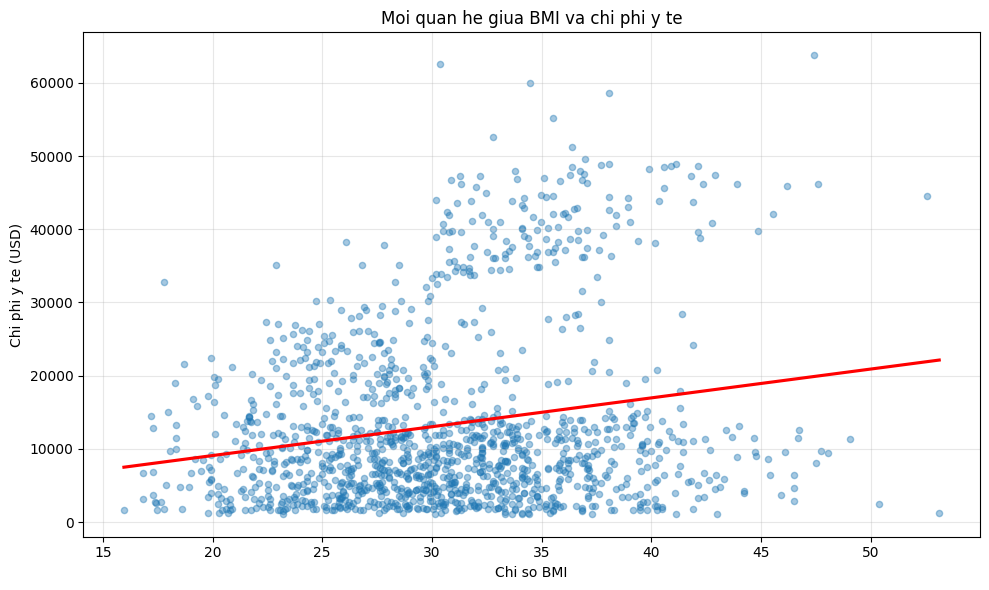

In [ ]:
# GIAI ĐOẠN 3 - BẢNG 3
# Phân tích mối liên hệ giữa BMI và chi phí y tế

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# Lấy dữ liệu đã làm sạch ở Giai đoạn 2
# Chỉ chọn các biến cần thiết cho phân tích
df_bmi = df_clean[['bmi', 'charges', 'smoker']].copy()

# Kiểm tra số quan sát
print("Số quan sát:", len(df_bmi))

# Tạo biểu đồ phân tán
plt.figure(figsize=(10, 6))

# Vẽ điểm dữ liệu và đường hồi quy tuyến tính
sns.regplot(
    data=df_bmi,
    x='bmi',
    y='charges',
    scatter_kws={'alpha': 0.4, 's': 20},
    line_kws={'color': 'red'},
    ci=None
)

# Đặt tiêu đề và nhãn trục
plt.title('Moi quan he giua BMI va chi phi y te')
plt.xlabel('Chi so BMI')
plt.ylabel('Chi phi y te (USD)')

# Hiển thị lưới
plt.grid(True, alpha=0.3)

# Điều chỉnh bố cục
plt.tight_layout()
plt.show()

In [ ]:
# BẢNG 3
# 4.3.2. Kiểm định tương quan BMI và chi phí y tế

# Tính hệ số tương quan Pearson
r, p_pearson = pearsonr(df_bmi['bmi'], df_bmi['charges'])

# Tính hệ số tương quan Spearman
rho, p_spearman = spearmanr(df_bmi['bmi'], df_bmi['charges'])

# Tính hệ số xác định R bình phương
r_squared = r**2

# Tạo bảng tổng hợp kết quả
bang_tuongquan = pd.DataFrame({
    'Phương pháp': ['Pearson', 'Spearman'],
    'Hệ số tương quan': [r, rho],
    'p-value': [p_pearson, p_spearman]
})

# Hiển thị bảng kết quả
display(bang_tuongquan)

# Hiển thị hệ số xác định
print("R bình phương:", round(r_squared, 4))

# Kiểm định giả thuyết H0 theo Pearson
alpha = 0.05

if p_pearson < alpha:
    print("Bác bỏ H0: Có tương quan tuyến tính có ý nghĩa thống kê")
else:
    print("Chưa đủ cơ sở bác bỏ H0")

,Phương pháp,Hệ số tương quan,p-value
0,Pearson,0.198401,2.468040e-13
1,Spearman,0.119585,1.163718e-05


R bình phương: 0.0394
Bác bỏ H0: Có tương quan tuyến tính có ý nghĩa thống kê


In [ ]:
# BẢNG 3
# 4.3.3. Tương quan BMI và chi phí theo tình trạng hút thuốc

# Tạo danh sách lưu kết quả
ket_qua = []

# Phân tích lần lượt hai nhóm hút thuốc và không hút thuốc
for trang_thai, nhom in df_bmi.groupby('smoker'):

    # Tính hệ số Pearson
    r, p = pearsonr(nhom['bmi'], nhom['charges'])

    # Tính hệ số Spearman
    rho, p_s = spearmanr(nhom['bmi'], nhom['charges'])

    # Lưu kết quả vào danh sách
    ket_qua.append({
        'Tình trạng hút thuốc': trang_thai,
        'Số quan sát': len(nhom),
        'Pearson': r,
        'Spearman': rho,
        'p-value Pearson': p
    })

# Tạo bảng kết quả
bang_bmi_smoker = pd.DataFrame(ket_qua)

# Hiển thị
display(bang_bmi_smoker)

,Tình trạng hút thuốc,Số quan sát,Pearson,Spearman,p-value Pearson
0,no,1063,0.084077,0.105373,6.091103e-03
1,yes,274,0.806481,0.834228,5.019669e-64


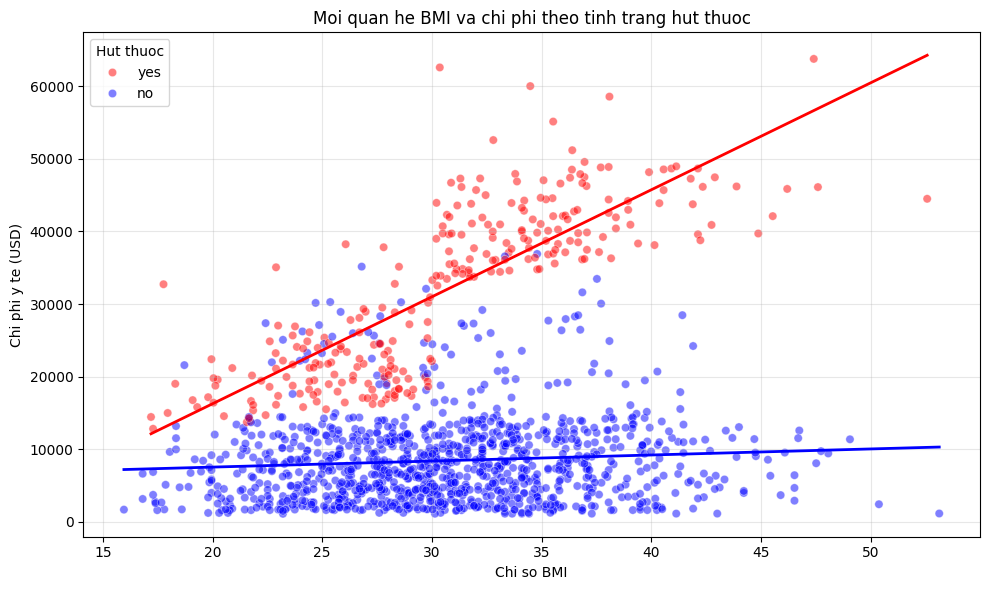

In [ ]:
# BẢNG 3
# Vẽ BMI và chi phí theo tình trạng hút thuốc

plt.figure(figsize=(10, 6))

# Biểu đồ phân tán, phân biệt màu theo smoker
sns.scatterplot(
    data=df_bmi,
    x='bmi',
    y='charges',
    hue='smoker',
    palette={'no': 'blue', 'yes': 'red'},
    alpha=0.5
)

# Vẽ đường hồi quy riêng cho từng nhóm
for trang_thai, mau in [('no', 'blue'), ('yes', 'red')]:
    nhom = df_bmi[df_bmi['smoker'] == trang_thai]

    # Ước lượng đường xu hướng tuyến tính
    a, b = np.polyfit(nhom['bmi'], nhom['charges'], 1)

    # Tạo các giá trị BMI để vẽ đường
    x_line = np.linspace(nhom['bmi'].min(), nhom['bmi'].max(), 100)
    y_line = a * x_line + b

    # Vẽ đường xu hướng
    plt.plot(x_line, y_line, color=mau, linewidth=2)

# Hoàn thiện biểu đồ
plt.title('Moi quan he BMI va chi phi theo tinh trang hut thuoc')
plt.xlabel('Chi so BMI')
plt.ylabel('Chi phi y te (USD)')
plt.legend(title='Hut thuoc')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 4.3.4. Phân nhóm BMI và so sánh chi phí

# Tạo biến phân nhóm BMI
df_bmi['Nhom_BMI'] = np.where(
    df_bmi['bmi'] >= 30,
    'BMI >= 30',
    'BMI < 30'
)

# Thống kê chi phí theo nhóm BMI và hút thuốc
bang_chiphi = df_bmi.groupby(
    ['smoker', 'Nhom_BMI']
)['charges'].agg(
    So_quan_sat='count',
    Trung_binh='mean',
    Trung_vi='median',
    Do_lech_chuan='std'
)

# Hiển thị bảng, làm tròn 2 chữ số
display(bang_chiphi.round(2))

So_quan_sat  Trung_binh  Trung_vi  Do_lech_chuan
smoker Nhom_BMI                                                   
no     BMI < 30           502     7977.03   6761.62        5839.23
       BMI >= 30          561     8855.53   8083.92        6102.64
yes    BMI < 30           129    21363.22  20167.34        5066.78
       BMI >= 30          145    41557.99  40904.20        6031.47

In [ ]:
# GIAI ĐOẠN 3 - BẢNG 4
# Thống kê chi phí y tế theo khu vực địa lý

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Lấy dữ liệu đã làm sạch ở Giai đoạn 2
# Giữ nguyên dữ liệu gốc của nhóm
df_region = df_clean[['region', 'charges', 'smoker']].copy()

# Quy định thứ tự các khu vực
region_order = [
    'northeast', 'northwest',
    'southeast', 'southwest'
]

# Thống kê chi phí y tế theo khu vực
bang_region = df_region.groupby('region')['charges'].agg(
    So_quan_sat='count',
    Trung_binh='mean',
    Trung_vi='median',
    Do_lech_chuan='std',
    Nho_nhat='min',
    Lon_nhat='max'
)

# Sắp xếp thứ tự các khu vực
bang_region = bang_region.reindex(region_order)

# Hiển thị bảng kết quả
print("Thống kê chi phí y tế theo khu vực:")
display(bang_region.round(2))

Thống kê chi phí y tế theo khu vực:


,So_quan_sat,Trung_binh,Trung_vi,Do_lech_chuan,Nho_nhat,Lon_nhat
region,,,,,,
northeast,324,13406.38,10057.65,11255.80,1694.80,58571.07
northwest,324,12450.84,8976.98,11073.13,1621.34,60021.40
southeast,364,14735.41,9294.13,13971.10,1121.87,63770.43
southwest,325,12346.94,8798.59,11557.18,1241.56,52590.83


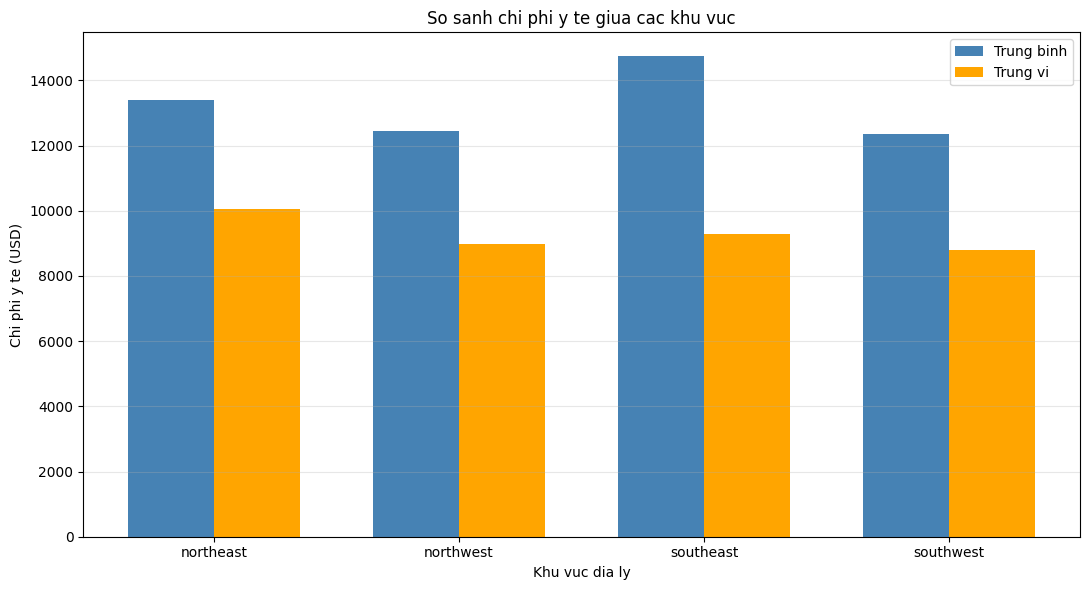

In [ ]:
# BẢNG 4
# 4.4.2. Vẽ biểu đồ so sánh chi phí giữa các khu vực

# Thiết lập vị trí của các cột
x = np.arange(len(region_order))
width = 0.35

# Tạo figure
plt.figure(figsize=(11, 6))

# Vẽ cột chi phí trung bình
plt.bar(
    x - width/2,
    bang_region['Trung_binh'],
    width,
    label='Trung binh',
    color='steelblue'
)

# Vẽ cột chi phí trung vị
plt.bar(
    x + width/2,
    bang_region['Trung_vi'],
    width,
    label='Trung vi',
    color='orange'
)

# Đặt tiêu đề và nhãn các trục
plt.title('So sanh chi phi y te giua cac khu vuc')
plt.xlabel('Khu vuc dia ly')
plt.ylabel('Chi phi y te (USD)')

# Hiển thị tên khu vực trên trục X
plt.xticks(x, region_order)

# Hiển thị chú thích và lưới
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Điều chỉnh bố cục
plt.tight_layout()
plt.show()

In [ ]:
# BẢNG 4
# 4.4.3. Kiểm định sự khác biệt chi phí giữa 4 khu vực

from scipy import stats
from statsmodels.stats.oneway import anova_oneway

# Tạo danh sách dữ liệu charges theo từng khu vực
nhom_chiphi = [
    df_region[df_region['region'] == kv]['charges'].values
    for kv in region_order
]

# 1. Kiểm định ANOVA một yếu tố
f_stat, p_anova = stats.f_oneway(*nhom_chiphi)

# 2. Kiểm định Levene: đồng nhất phương sai
lev_stat, p_levene = stats.levene(
    *nhom_chiphi,
    center='median'
)

# 3. Kiểm định Welch ANOVA
welch_result = anova_oneway(
    nhom_chiphi,
    use_var='unequal'
)

# 4. Kiểm định Kruskal-Wallis
h_stat, p_kruskal = stats.kruskal(*nhom_chiphi)

# 5. Tổng hợp kết quả kiểm định
bang_kiem_dinh = pd.DataFrame({
    'Kiem_dinh': [
        'ANOVA',
        'Levene',
        'Welch ANOVA',
        'Kruskal-Wallis'
    ],
    'Thong_ke': [
        f_stat,
        lev_stat,
        welch_result.statistic,
        h_stat
    ],
    'p_value': [
        p_anova,
        p_levene,
        welch_result.pvalue,
        p_kruskal
    ]
})

# Hiển thị kết quả
display(bang_kiem_dinh.round(6))

# 6. Đánh giá theo Welch ANOVA
alpha = 0.05

if welch_result.pvalue < alpha:
    print("Bac bo H0 theo Welch ANOVA")
else:
    print("Chua du co so bac bo H0 theo Welch ANOVA")

,Kiem_dinh,Thong_ke,p_value
0,ANOVA,2.926140,0.032763
1,Levene,5.553480,0.000869
2,Welch ANOVA,2.566223,0.053489
3,Kruskal-Wallis,4.622507,0.201620


Chua du co so bac bo H0 theo Welch ANOVA


In [ ]:
# BẢNG 4
# Đo lường mức độ khác biệt bằng Eta-squared

# Trung bình chi phí toàn bộ mẫu
mean_all = df_region['charges'].mean()

# Tổng bình phương giữa các nhóm
ss_between = sum(
    len(nhom) * (nhom['charges'].mean() - mean_all)**2
    for _, nhom in df_region.groupby('region')
)

# Tổng bình phương toàn bộ
ss_total = ((df_region['charges'] - mean_all)**2).sum()

# Hệ số Eta-squared
eta_squared = ss_between / ss_total

print("Eta-squared:", round(eta_squared, 4))
print("Ty le (%):", round(eta_squared * 100, 2))

Eta-squared: 0.0065
Ty le (%): 0.65


In [ ]:
# BẢNG 4
# 4.4.4. Kiểm tra tỷ lệ hút thuốc theo khu vực

# Đếm số người hút thuốc và không hút thuốc
bang_smoker = pd.crosstab(
    df_region['region'],
    df_region['smoker']
)

# Sắp xếp theo thứ tự khu vực
bang_smoker = bang_smoker.reindex(region_order)

# Tính tỷ lệ hút thuốc (%)
bang_smoker['Ty_le_hut_thuoc'] = (
    bang_smoker['yes'] / bang_smoker.sum(axis=1) * 100
)

# Hiển thị kết quả
display(bang_smoker.round(2))

smoker,no,yes,Ty_le_hut_thuoc
region,,,
northeast,257,67,20.68
northwest,266,58,17.90
southeast,273,91,25.00
southwest,267,58,17.85


In [ ]:
# Thống kê chi phí theo khu vực và tình trạng hút thuốc

bang_region_smoker = df_region.groupby(
    ['region', 'smoker']
)['charges'].agg(
    So_quan_sat='count',
    Trung_binh='mean',
    Trung_vi='median'
)

# Hiển thị kết quả
display(bang_region_smoker.round(2))

So_quan_sat  Trung_binh  Trung_vi
region    smoker                                   
northeast no              257     9165.53   8342.91
          yes              67    29673.54  28101.33
northwest no              266     8582.47   7259.23
          yes              58    30192.00  27489.00
southeast no              273     8032.22   6652.53
          yes              91    34845.00  37484.45
southwest no              267     8019.28   7348.14
          yes              58    32269.06  35165.26

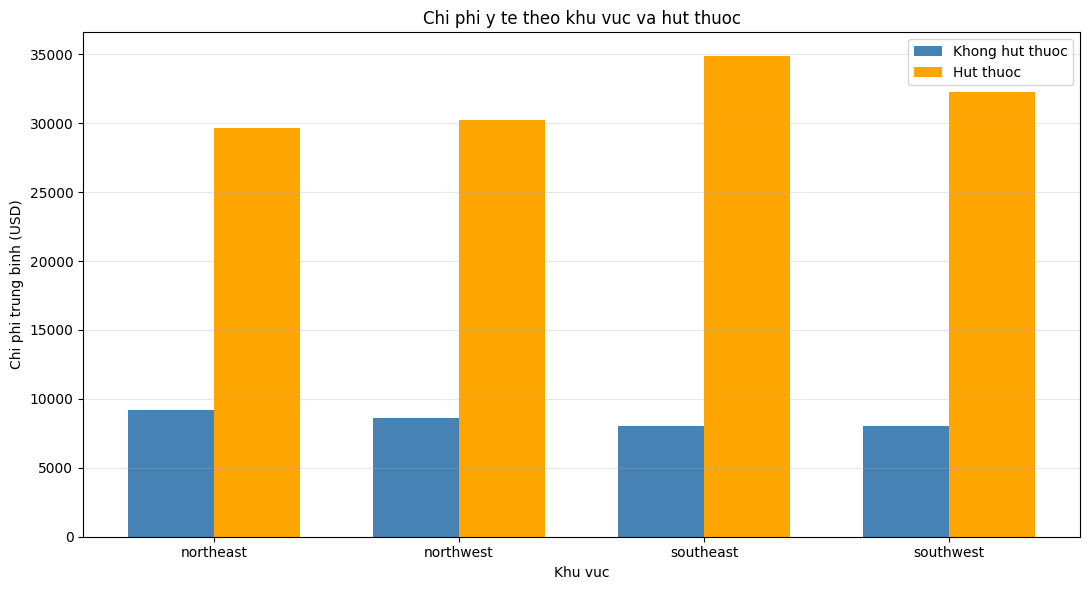

In [ ]:
# Vẽ biểu đồ cột chi phí theo khu vực và hút thuốc

# Tính chi phí trung bình của từng nhóm
mean_smoker = df_region.groupby(
    ['region', 'smoker']
)['charges'].mean().unstack()

# Sắp xếp thứ tự khu vực
mean_smoker = mean_smoker.reindex(region_order)

# Thiết lập vị trí cột
x = np.arange(len(region_order))
width = 0.35

plt.figure(figsize=(11, 6))

# Cột không hút thuốc
plt.bar(
    x - width/2,
    mean_smoker['no'],
    width,
    label='Khong hut thuoc',
    color='steelblue'
)

# Cột hút thuốc
plt.bar(
    x + width/2,
    mean_smoker['yes'],
    width,
    label='Hut thuoc',
    color='orange'
)

# Hoàn thiện biểu đồ
plt.title('Chi phi y te theo khu vuc va hut thuoc')
plt.xlabel('Khu vuc')
plt.ylabel('Chi phi trung binh (USD)')
plt.xticks(x, region_order)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Chuẩn hóa cơ cấu hút thuốc giữa các khu vực

# Tính tỷ lệ hút thuốc của toàn bộ mẫu
ty_le_chung = df_region['smoker'].value_counts(
    normalize=True
).reindex(['no', 'yes'])

# Tính chi phí trung bình theo khu vực và hút thuốc
mean_by_group = df_region.pivot_table(
    index='region',
    columns='smoker',
    values='charges',
    aggfunc='mean'
)

# Tính chi phí trung bình đã chuẩn hóa cơ cấu
mean_adjusted = (
    mean_by_group * ty_le_chung
).sum(axis=1)

# Tạo bảng so sánh trước và sau điều chỉnh
bang_dieu_chinh = pd.DataFrame({
    'Trung_binh_goc': df_region.groupby(
        'region'
    )['charges'].mean(),
    'Trung_binh_dieu_chinh': mean_adjusted
})

# Sắp xếp các khu vực
bang_dieu_chinh = bang_dieu_chinh.reindex(region_order)

# Hiển thị
display(bang_dieu_chinh.round(2))

,Trung_binh_goc,Trung_binh_dieu_chinh
region,,
northeast,13406.38,13368.37
northwest,12450.84,13011.05
southeast,14735.41,13527.13
southwest,12346.94,12988.95


In [ ]:
# BẢNG 5
# MỐI QUAN HỆ BIẾN ĐỊNH LƯỢNG VỚI CHI PHÍ Y TẾ
# Chọn biến cho phân tích
numeric_cols = ['age', 'bmi', 'children', 'charges']

# Tính hệ số tương quan Pearson
corr_matrix = df[numeric_cols].corr(method='pearson')

# Hiển thị hệ số tương quan từng cặp biến
display(corr_matrix.round(3))

,age,bmi,children,charges
age,1.000,0.109,0.042,0.299
bmi,0.109,1.000,0.013,0.198
children,0.042,0.013,1.000,0.068
charges,0.299,0.198,0.068,1.000


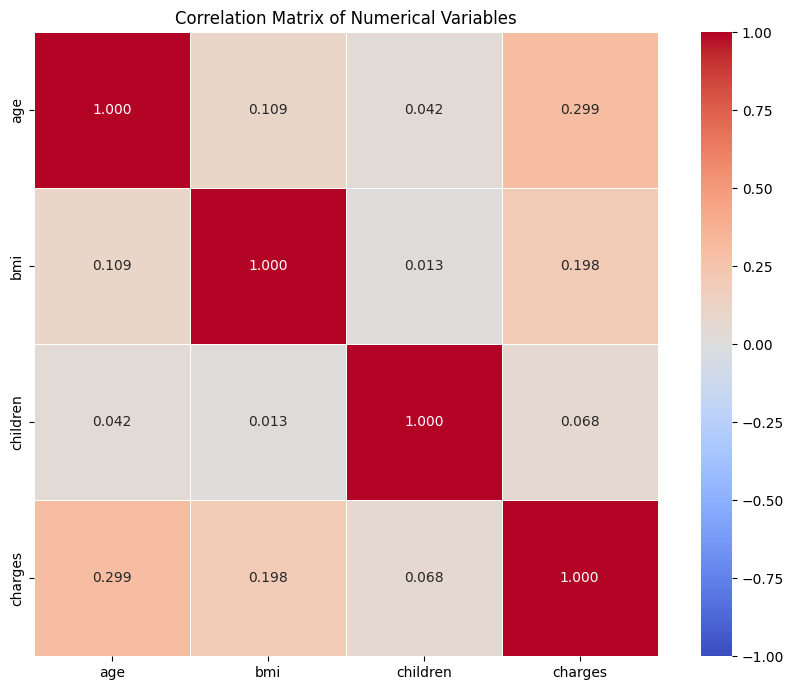

In [ ]:
#BẢNG 5
# Tạo biểu đồ heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()


In [ ]:
# Bảng 5
# Kiểm định tương quan

# Nhập hàm kiểm định tương quan Pearson
from scipy.stats import pearsonr

# Lựa chọn các biến độc lập cần kiểm định
variables = ['age', 'bmi', 'children']

# Thiết lập mức ý nghĩa thống kê 5%
alpha = 0.05

# Kiểm định tương quan giữa từng biến và chi phí y tế
for var in variables:
    r, p_value = pearsonr(df[var], df['charges'])

    print(f"\nBiến kiểm định: {var}")
    print(f"Hệ số tương quan Pearson: {r:.4f}")
    print(f"Giá trị p-value: {p_value:.6f}")

    if p_value < alpha:
        print("Bác bỏ H0: Mối tương quan có ý nghĩa thống kê")
    else:
        print("Chưa đủ cơ sở bác bỏ H0: Chưa có bằng chứng về mối tương quan tuyến tính có ý nghĩa thống kê")



Biến kiểm định: age
Hệ số tương quan Pearson: 0.2990
Giá trị p-value: 0.000000
Bác bỏ H0: Mối tương quan có ý nghĩa thống kê

Biến kiểm định: bmi
Hệ số tương quan Pearson: 0.1983
Giá trị p-value: 0.000000
Bác bỏ H0: Mối tương quan có ý nghĩa thống kê

Biến kiểm định: children
Hệ số tương quan Pearson: 0.0680
Giá trị p-value: 0.012852
Bác bỏ H0: Mối tương quan có ý nghĩa thống kê
